# Effective rank vs residual-stream width

Telephone (3× mess3) at d_model 60 / 120 / 240. Uses the committed
`experiments/fig13_width_sweep/results.json` cache — exactly the 13 runs
the published figure drew (the d240 point is a 3-seed mean; see
`experiments/SEED_MANIFEST.md`). Pass `--refresh` to recompute from
checkpoints.


In [1]:
import os, sys
from pathlib import Path

REPO = Path.cwd().resolve()
if not (REPO / 'plotting').is_dir():
    REPO = REPO.parent          # launched from notebooks/
assert (REPO / 'plotting').is_dir(), REPO
sys.path.insert(0, str(REPO))

# Point FACTORED_REPS_DATA at the directory holding experiments/<figure>/runs/<run>/
# {checkpoints,mlruns} (default: this repo). Must be set BEFORE this import.
import fwh_core, plotting.lib.runs as runs
assert Path(fwh_core.__file__).is_relative_to(REPO), 'fwh_core resolves outside this repo'
FIG = Path(os.path.relpath(REPO / 'figures')); FIG.mkdir(exist_ok=True)
ANALYSIS = REPO / 'analysis'
from IPython.display import Image, display
def show(*names, width=820):
    for n in names:
        print(n)
        display(Image(filename=FIG / f'{n}.png', width=width))


  cached  d= 60 telephone_mess3_d60_canonical_s2001_50k
  cached  d= 60 telephone_mess3_d60_canonical_s2002_50k
  cached  d= 60 telephone_mess3_d60_canonical_s2003_50k
  cached  d= 60 telephone_mess3_d60_canonical_s2004_50k
  cached  d= 60 telephone_mess3_d60_canonical_s2005_50k
  cached  d=120 telephone_mess3_canonical_50k
  cached  d=120 telephone_mess3_canonical_s401_50k
  cached  d=120 telephone_mess3_canonical_s402_50k
  cached  d=120 telephone_mess3_canonical_s403_50k
  cached  d=120 telephone_mess3_canonical_s404_50k
  cached  d=240 telephone_mess3_d240_canonical_s2101_50k
  cached  d=240 telephone_mess3_d240_canonical_s2102_50k
  cached  d=240 telephone_mess3_d240_canonical_s2103_50k

  d_model | seeds |  nc@80%      |  nc@95%      |  PR            | factored | joint
       60 |     5 |   5.0 [5,5] |   7.0 [7,7] |  5.78 [5.40,6.13] |       24 | 728
      120 |     5 |   5.0 [5,5] |   7.4 [7,8] |  5.73 [5.08,6.12] |       24 | 728
      240 |     3 |   5.0 [5,5] |   9.3 [9,10] |

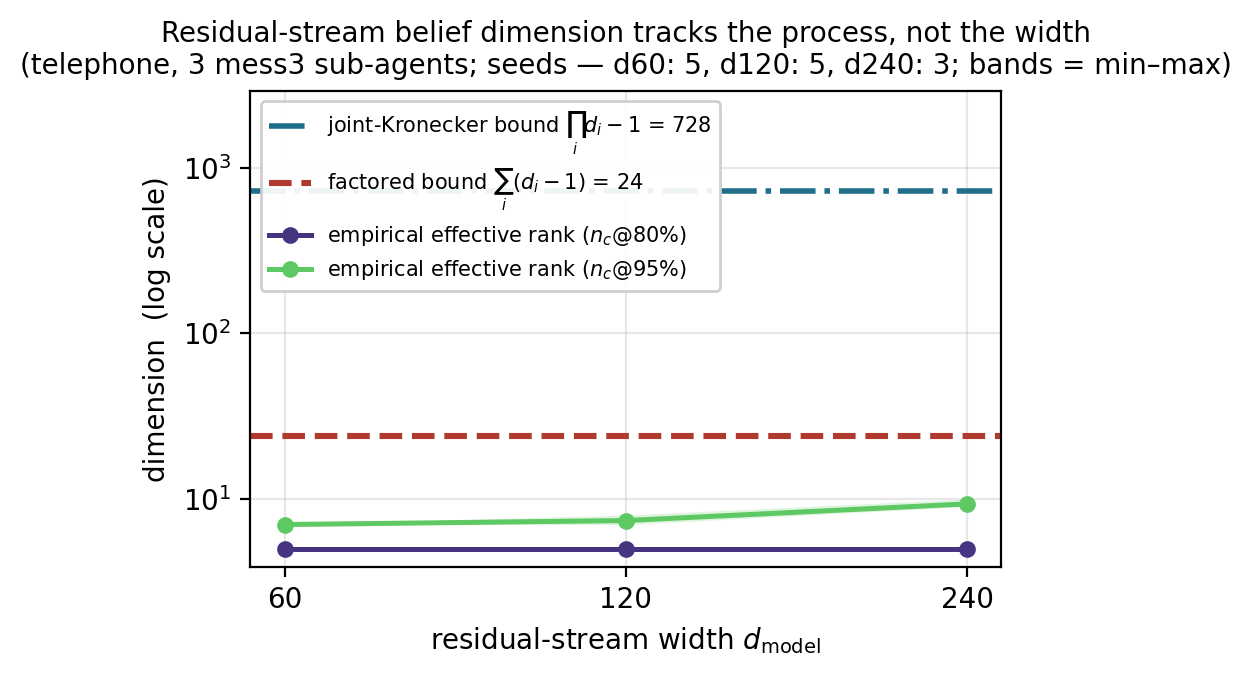

In [2]:
import subprocess
r = subprocess.run([sys.executable, 'experiments/fig13_width_sweep/analysis.py',
                    '--out', 'figures/effective_rank_vs_width.png'],   # relative to cwd=REPO
                   cwd=REPO, capture_output=True, text=True)
print(r.stdout[-1200:]); assert r.returncode == 0, r.stderr[-2000:]
show('effective_rank_vs_width', width=620)
